# Disease Prediction — Model Training and Evaluation

This notebook trains four classifiers on the supplied symptom-based dataset and compares their performance on the separate `Testing.csv` file.

**Algorithms:** Support Vector Machine (SVM), Logistic Regression, Random Forest, and XGBoost.

**Dataset:** The supplied files use symptom indicator columns and the target column `prognosis`. They do not contain age or blood-test measurements and are not the UCI heart disease, diabetes, or breast cancer datasets.

> Educational demonstration only. This model is not a clinically validated diagnostic system and must not be used to make medical decisions.

## 1. Install dependencies
Run once in the active notebook kernel.

In [1]:
%pip install -r ../requirements.txt

Note: you may need to restart the kernel to use updated packages.


## 2. Imports and project paths

In [2]:
from pathlib import Path
import json
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)
from xgboost import XGBClassifier

warnings.filterwarnings("ignore", category=UserWarning)

# Notebook is stored in notebooks/, so the project root is its parent.
PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = PROJECT_DIR / "data"
MODEL_DIR = PROJECT_DIR / "models"
REPORT_DIR = PROJECT_DIR / "reports"
MODEL_DIR.mkdir(exist_ok=True)
REPORT_DIR.mkdir(exist_ok=True)

TRAIN_PATH = DATA_DIR / "Training.csv"
TEST_PATH = DATA_DIR / "Testing.csv"
print("Project folder:", PROJECT_DIR.resolve())
print("Training file found:", TRAIN_PATH.exists())
print("Testing file found:", TEST_PATH.exists())

Project folder: C:\Disease_Prediction_task
Training file found: True
Testing file found: True


## 3. Load and inspect the data

In [3]:
if not TRAIN_PATH.exists() or not TEST_PATH.exists():
    raise FileNotFoundError(
        "Could not find data/Training.csv and data/Testing.csv. "
        "Open this notebook from the project folder or update PROJECT_DIR."
    )

train_df = pd.read_csv(TRAIN_PATH)
test_df = pd.read_csv(TEST_PATH)

# Remove blank spreadsheet-export columns such as Unnamed: 133.
train_df = train_df.loc[:, ~train_df.columns.astype(str).str.match(r"^Unnamed")]
test_df = test_df.loc[:, ~test_df.columns.astype(str).str.match(r"^Unnamed")]

TARGET = "prognosis"
if TARGET not in train_df.columns or TARGET not in test_df.columns:
    raise ValueError(f"Both CSV files must contain the '{TARGET}' target column.")

print(f"Training rows/columns: {train_df.shape}")
print(f"Testing rows/columns: {test_df.shape}")
print(f"Number of training classes: {train_df[TARGET].nunique()}")
print(f"Missing values in training: {int(train_df.isna().sum().sum())}")
print(f"Missing values in testing: {int(test_df.isna().sum().sum())}")
display(train_df.head())
display(train_df[TARGET].value_counts().rename_axis("prognosis").reset_index(name="count"))

Training rows/columns: (4920, 133)
Testing rows/columns: (42, 133)
Number of training classes: 41
Missing values in training: 0
Missing values in testing: 0


,itching,skin_rash,nodal_skin_eruptions,continuous_sneezing,shivering,chills,joint_pain,stomach_pain,acidity,ulcers_on_tongue,...,blackheads,scurring,skin_peeling,silver_like_dusting,small_dents_in_nails,inflammatory_nails,blister,red_sore_around_nose,yellow_crust_ooze,prognosis
0,1,1,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,Fungal infection
1,0,1,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,Fungal infection
2,1,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,Fungal infection
3,1,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,Fungal infection
4,1,1,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,Fungal infection


,prognosis,count
0,Fungal infection,120
1,Allergy,120
2,GERD,120
3,Chronic cholestasis,120
4,Drug Reaction,120
5,Peptic ulcer diseae,120
6,AIDS,120
7,Diabetes,120
8,Gastroenteritis,120
9,Bronchial Asthma,120


## 4. Prepare feature columns and target labels

In [4]:
feature_columns = [column for column in train_df.columns if column != TARGET]

missing_test_features = sorted(set(feature_columns) - set(test_df.columns))
extra_test_features = sorted(set(test_df.columns) - set(feature_columns) - {TARGET})
if missing_test_features:
    raise ValueError(f"Testing.csv is missing these training features: {missing_test_features}")
if extra_test_features:
    print("Extra test columns ignored:", extra_test_features)

X_train = train_df[feature_columns].copy()
X_test = test_df[feature_columns].copy()
y_train_text = train_df[TARGET].astype(str).str.strip()
y_test_text = test_df[TARGET].astype(str).str.strip()

# Coerce features to numeric; use training medians for any missing values.
X_train = X_train.apply(pd.to_numeric, errors="coerce")
X_test = X_test.apply(pd.to_numeric, errors="coerce")
training_medians = X_train.median(numeric_only=True).fillna(0)
X_train = X_train.fillna(training_medians).fillna(0)
X_test = X_test.fillna(training_medians).fillna(0)

label_encoder = LabelEncoder()
y_train = label_encoder.fit_transform(y_train_text)
unknown_labels = sorted(set(y_test_text) - set(label_encoder.classes_))
if unknown_labels:
    raise ValueError(f"Testing.csv contains labels not found in training: {unknown_labels}")
y_test = label_encoder.transform(y_test_text)

print("Feature count:", len(feature_columns))
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Class count:", len(label_encoder.classes_))

Feature count: 132
Training samples: 4920
Testing samples: 42
Class count: 41


## 5. Define the classifiers

In [5]:
models = {
    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", SVC(kernel="rbf", class_weight="balanced", random_state=42))
    ]),
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            max_iter=3000, class_weight="balanced", random_state=42
        ))
    ]),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, class_weight="balanced_subsample",
        random_state=42, n_jobs=-1
    ),
    "XGBoost": XGBClassifier(
        n_estimators=250, max_depth=6, learning_rate=0.08,
        subsample=0.9, colsample_bytree=0.9,
        objective="multi:softprob", eval_metric="mlogloss",
        tree_method="hist", random_state=42, n_jobs=-1
    )
}
print("Ready:", ", ".join(models.keys()))

Ready: SVM, Logistic Regression, Random Forest, XGBoost


## 6. Train and evaluate models

In [6]:
results = []
trained_models = {}

for model_name, model in models.items():
    print(f"Training {model_name}...")
    model.fit(X_train, y_train)
    predicted = model.predict(X_test)

    row = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predicted),
        "Macro Precision": precision_score(y_test, predicted, average="macro", zero_division=0),
        "Macro Recall": recall_score(y_test, predicted, average="macro", zero_division=0),
        "Macro F1-score": f1_score(y_test, predicted, average="macro", zero_division=0)
    }
    results.append(row)
    trained_models[model_name] = model

    file_stem = model_name.lower().replace(" ", "_")
    joblib.dump(model, MODEL_DIR / f"{file_stem}.joblib")
    print(f"  Accuracy: {row['Accuracy']:.3f} | Macro F1: {row['Macro F1-score']:.3f}")

results_df = pd.DataFrame(results).sort_values("Macro F1-score", ascending=False).reset_index(drop=True)
display(results_df.style.format({
    "Accuracy": "{:.2%}", "Macro Precision": "{:.2%}",
    "Macro Recall": "{:.2%}", "Macro F1-score": "{:.2%}"
}))
results_df.to_csv(REPORT_DIR / "model_comparison.csv", index=False)

joblib.dump(label_encoder, MODEL_DIR / "label_encoder.joblib")
with open(MODEL_DIR / "feature_columns.json", "w", encoding="utf-8") as f:
    json.dump(feature_columns, f, indent=2)
with open(MODEL_DIR / "label_classes.json", "w", encoding="utf-8") as f:
    json.dump(label_encoder.classes_.tolist(), f, indent=2)

print("Saved trained models to:", MODEL_DIR.resolve())

Training SVM...
  Accuracy: 0.976 | Macro F1: 0.984
Training Logistic Regression...
  Accuracy: 0.976 | Macro F1: 0.984
Training Random Forest...
  Accuracy: 0.976 | Macro F1: 0.984
Training XGBoost...
  Accuracy: 0.976 | Macro F1: 0.984


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1-score
0,SVM,97.62%,98.78%,98.78%,98.37%
1,Logistic Regression,97.62%,98.78%,98.78%,98.37%
2,Random Forest,97.62%,98.78%,98.78%,98.37%
3,XGBoost,97.62%,98.78%,98.78%,98.37%


Saved trained models to: C:\Disease_Prediction_task\models


## 7. Plot model comparison

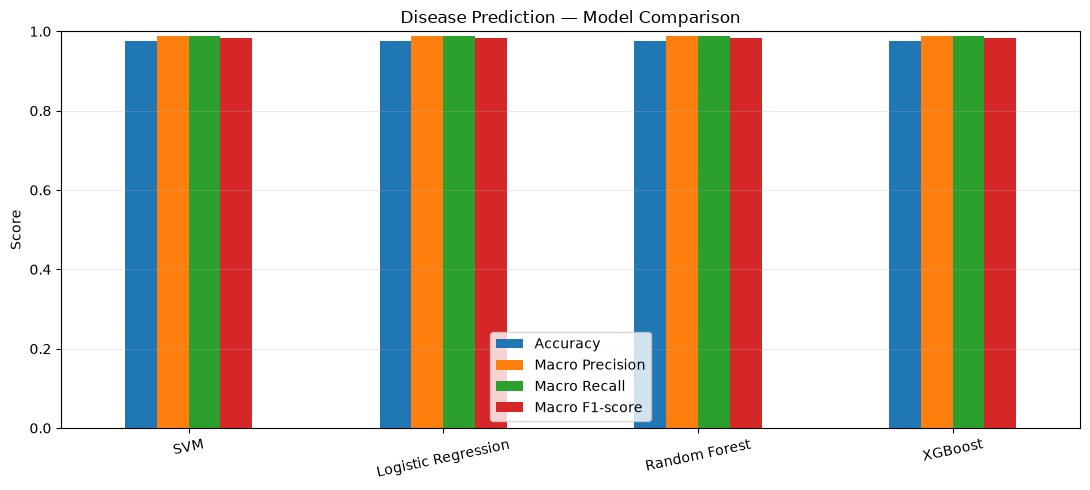

In [7]:
metrics = results_df.set_index("Model")[["Accuracy", "Macro Precision", "Macro Recall", "Macro F1-score"]]
ax = metrics.plot(kind="bar", figsize=(11, 5), ylim=(0, 1), rot=12)
ax.set_title("Disease Prediction — Model Comparison")
ax.set_ylabel("Score")
ax.set_xlabel("")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

## 8. Detailed report for the top model

In [8]:
best_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_name]
best_predictions = best_model.predict(X_test)

print("Top model by macro F1-score:", best_name)
print(classification_report(
    y_test,
    best_predictions,
    labels=np.arange(len(label_encoder.classes_)),
    target_names=label_encoder.classes_,
    zero_division=0
))

Top model by macro F1-score: SVM
                                         precision    recall  f1-score   support

(vertigo) Paroymsal  Positional Vertigo       1.00      1.00      1.00         1
                                   AIDS       1.00      1.00      1.00         1
                                   Acne       1.00      1.00      1.00         1
                    Alcoholic hepatitis       1.00      1.00      1.00         1
                                Allergy       1.00      1.00      1.00         1
                              Arthritis       1.00      1.00      1.00         1
                       Bronchial Asthma       1.00      1.00      1.00         1
                   Cervical spondylosis       1.00      1.00      1.00         1
                            Chicken pox       1.00      1.00      1.00         1
                    Chronic cholestasis       1.00      1.00      1.00         1
                            Common Cold       1.00      1.00      1.00     

## 9. Confusion matrix for the best model

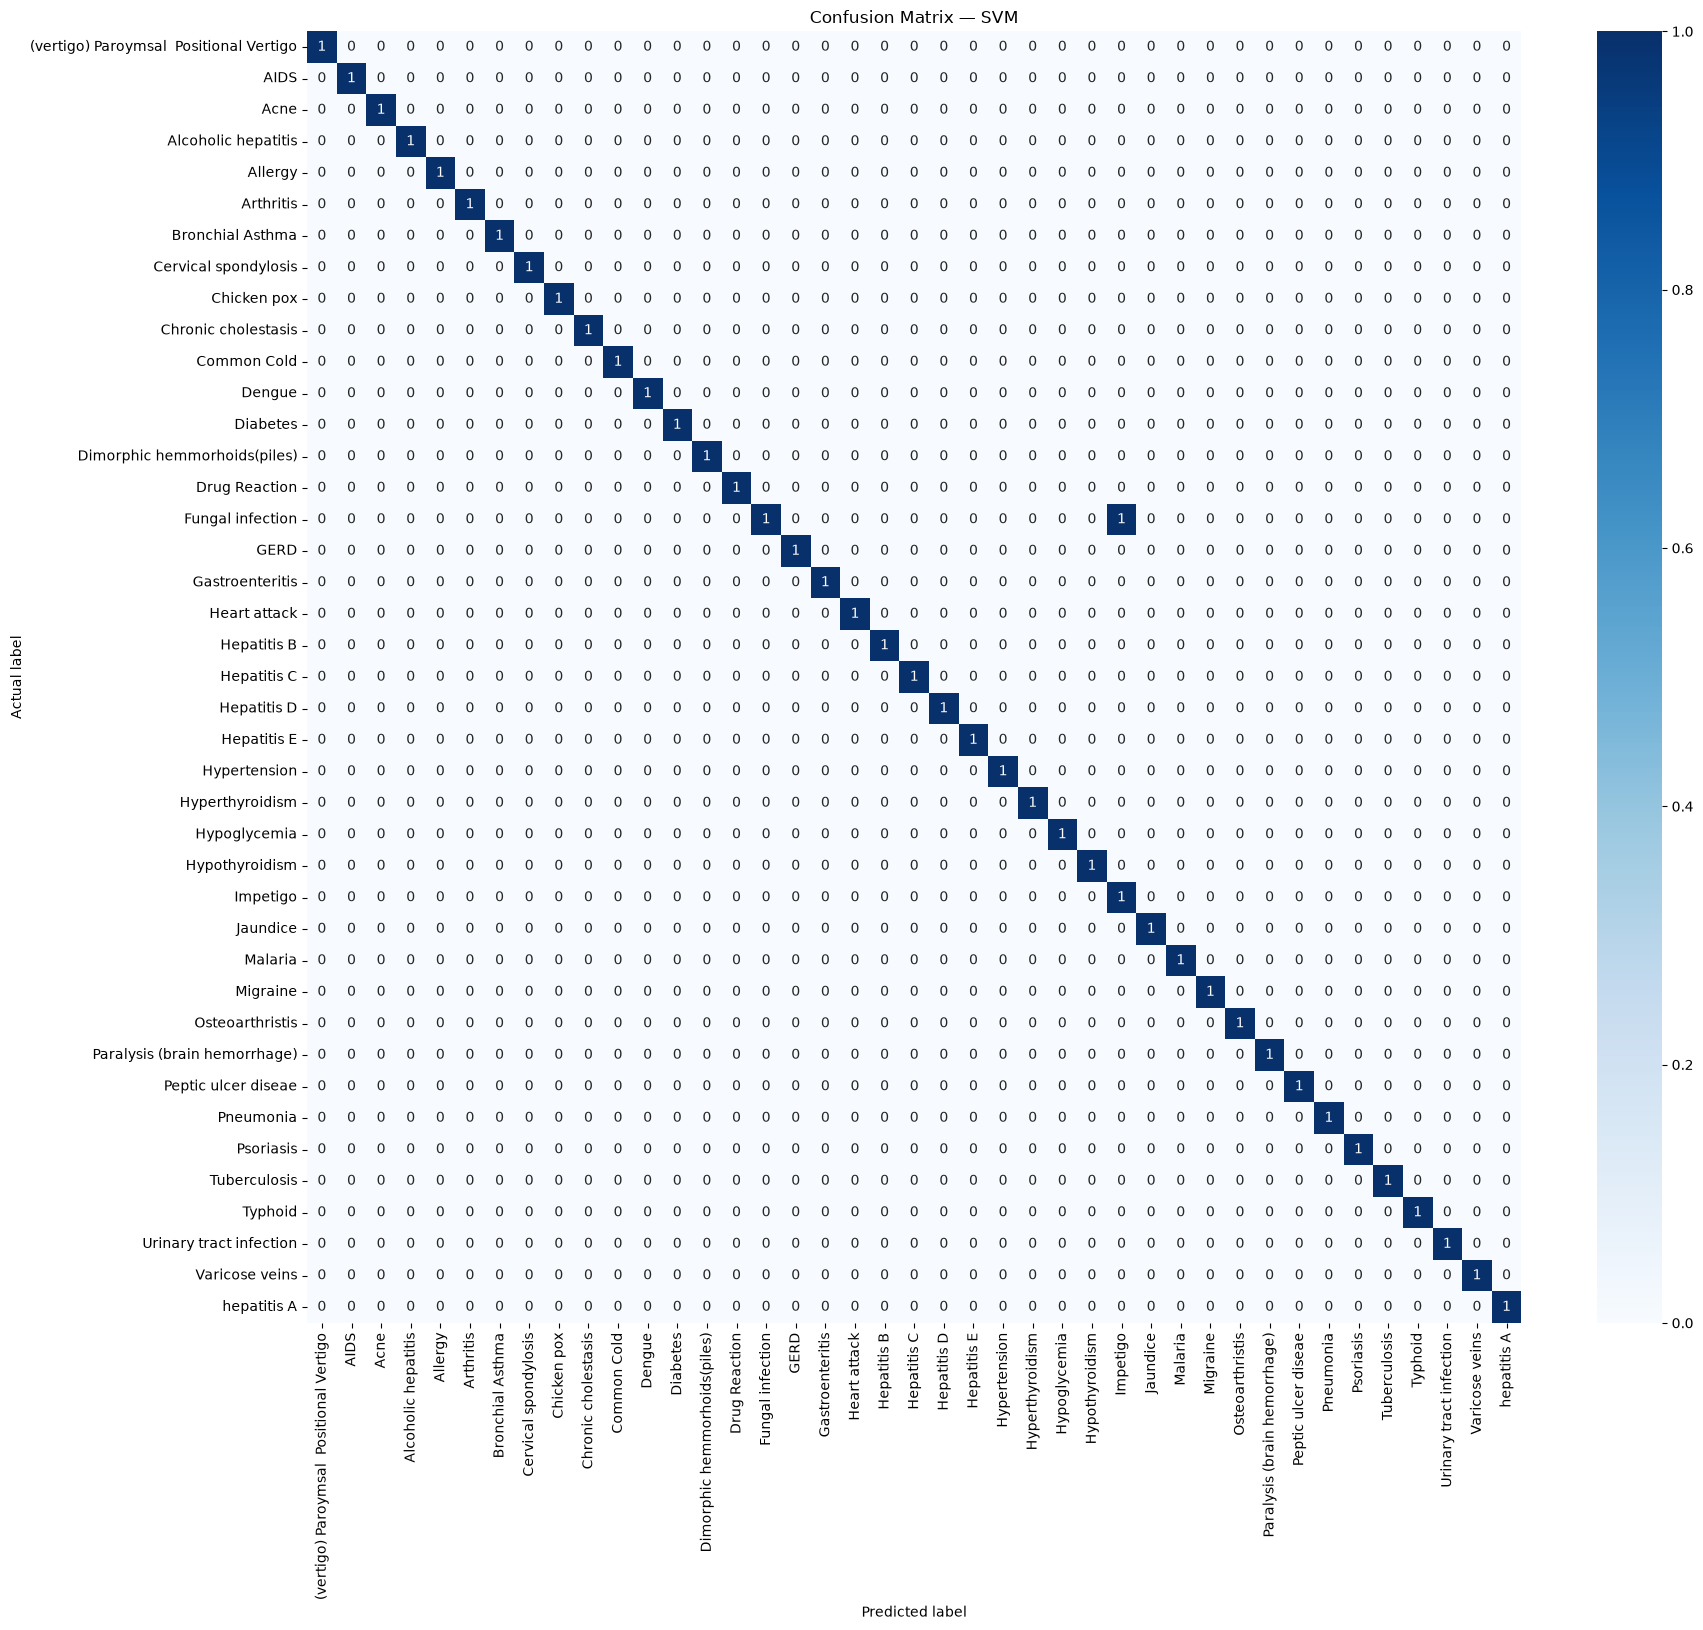

In [9]:
labels_present = sorted(set(y_test.tolist()) | set(np.asarray(best_predictions).tolist()))
names_present = label_encoder.inverse_transform(np.asarray(labels_present, dtype=int))
cm = confusion_matrix(y_test, best_predictions, labels=labels_present)

plt.figure(figsize=(max(8, len(names_present) * 0.45), max(6, len(names_present) * 0.4)))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=names_present, yticklabels=names_present)
plt.title(f"Confusion Matrix — {best_name}")
plt.xlabel("Predicted label")
plt.ylabel("Actual label")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## 10. Test one example row

In [10]:
sample = X_test.iloc[[0]]
predicted_class_id = int(best_model.predict(sample)[0])
predicted_label = label_encoder.inverse_transform([predicted_class_id])[0]
actual_label = y_test_text.iloc[0]
active_features = [feature for feature, value in sample.iloc[0].items() if value == 1]

print("Predicted class:", predicted_label)
print("Actual test label:", actual_label)
print("Active symptom features:", active_features)

Predicted class: Fungal infection
Actual test label: Fungal infection
Active symptom features: ['itching', 'skin_rash', 'nodal_skin_eruptions', 'dischromic _patches']


## 11. Export model metadata for the website

In [11]:
metadata = {
    "target_column": TARGET,
    "feature_count": len(feature_columns),
    "class_count": len(label_encoder.classes_),
    "best_model_by_macro_f1": best_name,
    "educational_use_only": True
}
with open(MODEL_DIR / "metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2)

print("Model artifacts:", sorted(p.name for p in MODEL_DIR.iterdir()))
print("Metrics report:", (REPORT_DIR / "model_comparison.csv").resolve())

Model artifacts: ['.gitkeep', 'feature_columns.json', 'label_classes.json', 'label_encoder.joblib', 'logistic_regression.joblib', 'metadata.json', 'random_forest.joblib', 'svm.joblib', 'xgboost.joblib']
Metrics report: C:\Disease_Prediction_task\reports\model_comparison.csv
